[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

构建 oracle 与扩散算子，在本地放大目标态并保留可选云端示例。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。量子云步骤默认关闭；只有需要访问云端时才将 `RUN_ON_QCLOUD` 改为 `True`，并在启动 Jupyter 前准备好 `APIKEY` 环境变量。

In [1]:
RUN_ON_QCLOUD = False

if RUN_ON_QCLOUD:
    import os
    if not os.environ.get("APIKEY"):
        raise ValueError("请先设置 APIKEY 环境变量，再开启量子云步骤。")


# Grover搜索算法

In [2]:
import os
from math import ceil, pi, sqrt, floor
from typing import List
from pyqpanda3.core import X, H, Z, measure, QProg, CPUQVM
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

In [3]:
def init_state(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q)
    return prog

In [4]:
def build_oracle(qubits: List[int], dst: str) -> QProg:
    prog = QProg()
    n_qubits = len(qubits)
    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    
    prog << Z(qubits[0]).control(qubits[1:])

    for idx in range(n_qubits):
        if dst[idx] == '0':
            prog << X(qubits[n_qubits - 1 - idx])
    return prog

In [5]:
def build_diffusion(qubits: List[int]) -> QProg:
    prog = QProg()
    for q in qubits:
        prog << H(q) << X(q)
    
    prog << Z(qubits[0]).control(qubits[1:])

    for q in qubits:
        prog << X(q) << H(q)
    return prog

In [6]:
n_qubits = 3
working_qubits = [0, 1, 2]
dst = '010'

prog = QProg()
prog << init_state(working_qubits)

iterations = pi/4*sqrt(2**n_qubits)
iterations = floor(iterations)

oracle = build_oracle(working_qubits, dst)
diffusion = build_diffusion(working_qubits)

for i in range(iterations):
	prog << oracle
	prog << diffusion

for q in working_qubits:
	prog << measure(q, q)

## 本地模拟

先用 CPUQVM 验证目标态概率，再按需开启下一步的量子云运行。

In [7]:
qvm = CPUQVM()
qvm.run(prog, 1000)
local_counts = qvm.result().get_counts()
print(local_counts)
print("目标态：", dst)


{'101': 9, '000': 5, '100': 7, '001': 12, '010': 937, '011': 12, '110': 13, '111': 5}
目标态： 010


## 可选：量子云运行

In [8]:
if RUN_ON_QCLOUD:
    APIKEY = os.getenv('APIKEY')
    service = QCloudService(APIKEY)

    # 查看可用计算后端
    backends = service.backends()
    print(backends)

    # WK_C180是真机，选择使用这个后端
    backend = service.backend('WK_C180')
    options = QCloudOptions()
    job = backend.run(prog, 10000, options)
    # 查询任务结果，计算时间与任务队列中任务数量有关
    result = job.result().get_probs()
    print(result)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

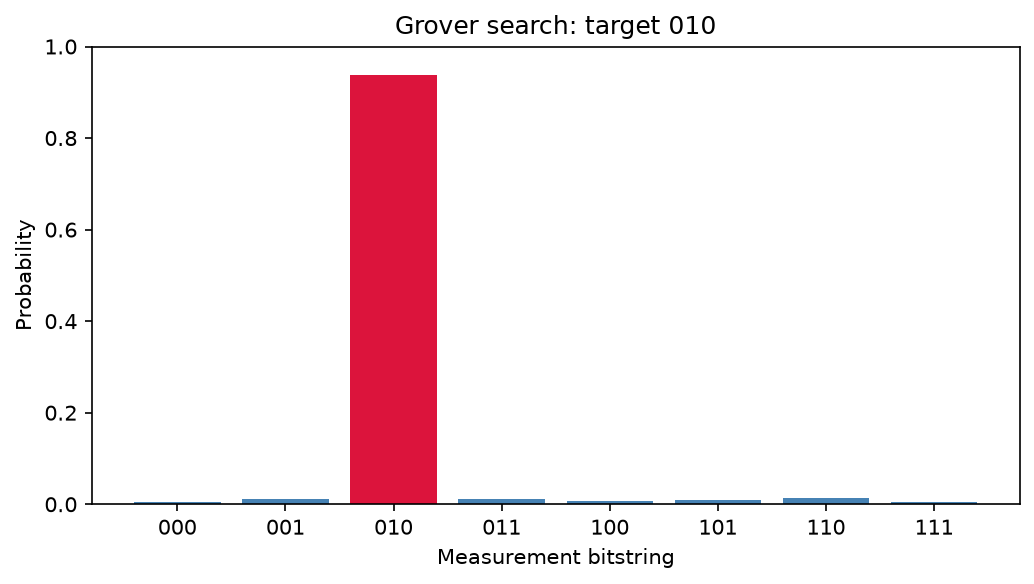

In [9]:
from io import BytesIO
from IPython.display import Image, display
import matplotlib.pyplot as plt

states = [format(i, f"0{n_qubits}b") for i in range(2**n_qubits)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(states, [local_counts.get(state, 0) / sum(local_counts.values()) for state in states], color=["crimson" if state == dst else "steelblue" for state in states])
ax.set(xlabel="Measurement bitstring", ylabel="Probability", ylim=(0, 1), title=f"Grover search: target {dst}")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))


## 附录：从相位标记到 Grover 的二维旋转

阅读顺序：**问题与 oracle → 扩散反射 → 旋转推导 → 迭代次数 → 原代码验证**。符号约定：$i^2=-1$，$\langle u|v\rangle$ 为内积，$|u\rangle\langle u|$ 为到归一化态 $|u\rangle$ 的投影。以下仅用本地小线路，保留 `RUN_ON_QCLOUD = False`。

### B.1 搜索的输入是什么：能检验答案，不等于已知道答案

设 $N=2^n$ 个索引，判别函数 $f(x)\in\{0,1\}$，有 $M$ 个满足 $f(x)=1$ 的解。目标是输出任意一个解。均匀初态为

$$
|s\rangle=H^{\otimes n}|0^n\rangle=\frac1{\sqrt N}\sum_{x=0}^{N-1}|x\rangle.
$$

可逆检验器 $U_f|x\rangle|b\rangle=|x\rangle|b\oplus f(x)\rangle$ 若作用于辅助态 $|-\rangle=(|0\rangle-|1\rangle)/\sqrt2$，由 $X|-\rangle=-|-\rangle$ 得

$$
U_f|x\rangle|-\rangle=(-1)^{f(x)}|x\rangle|-\rangle.
$$

辅助态没有改变，搜索寄存器等效地经过相位 oracle

$$
O_f|x\rangle=(-1)^{f(x)}|x\rangle,
\qquad O_f=I-2\Pi_{\mathrm{good}},
\quad\Pi_{\mathrm{good}}=\sum_{f(x)=1}|x\rangle\langle x|.
$$

单独的相位翻转不改变计算基测量概率，后续必须通过干涉放大振幅。实际 oracle 要把判别条件编译为可逆线路，并清除计算过程的垃圾辅助位；其代价不能忽略。

本篇 `dst='010'` 是**预先指定答案的演示 oracle**，用于理解算法，并非未知答案的实际应用。字符串按 $q_2q_1q_0$ 读取，索引为 2。`build_oracle` 把目标中为 0 的位先用 X 翻转，使该目标临时成为 $|111\rangle$；多控 Z 只翻转此态的相位，再用 X 撤销编码。代码用 `qubits[n_qubits-1-idx]` 对应字符串从高位到低位的顺序；本例 `working_qubits=[0,1,2]`。

### B.2 扩散算子：对振幅的均值反演

教材常用 $D=2|s\rangle\langle s|-I$。对 $|\psi\rangle=\sum_x a_x|x\rangle$，令复振幅均值 $\bar a=N^{-1}\sum_xa_x$，则

$$
D|\psi\rangle=\sum_x(2\bar a-a_x)|x\rangle.
$$

它反演的是**复振幅**，不是概率。相位标记把目标振幅变号，随后均值反演使目标振幅增大。由于 $H^{\otimes n}|0^n\rangle=|s\rangle$，

$$
D=H^{\otimes n}(2|0^n\rangle\langle0^n|-I)H^{\otimes n}.
$$

原 `build_diffusion` 的多控 Z 与两侧 X 实现 $I-2|0^n\rangle\langle0^n|$，所以实际实现的是

$$
D_{\mathrm{code}}=H^{\otimes n}(I-2|0^n\rangle\langle0^n|)H^{\otimes n}=-D.
$$

原循环先 oracle、后 diffusion，因此一轮是 $G_{\mathrm{code}}=-DO_f=-G$。固定执行 $r$ 轮只多出全局相位 $(-1)^r$，测量概率相同。若今后把整轮作为受控子程序，这个负号可能变成相对相位，需要重新处理，不能随意丢弃。


### B.3 严格推导：高维搜索为何只需分析二维平面

先设 $0<M<N$，定义正交归一化态

$$
|b\rangle=\frac1{\sqrt{N-M}}\sum_{f(x)=0}|x\rangle,
\qquad |g\rangle=\frac1{\sqrt M}\sum_{f(x)=1}|x\rangle.
$$

令 $\theta=\arcsin\sqrt{M/N}\in(0,\pi/2)$，则

$$
|s\rangle=\cos\theta|b\rangle+\sin\theta|g\rangle.
$$

oracle 对 $|b\rangle$ 不变、对 $|g\rangle$ 变号；$D$ 是关于 $|s\rangle$ 的反射。二者都保持 $\operatorname{span}\{|b\rangle,|g\rangle\}$，所以从 $|s\rangle$ 出发始终留在该二维子空间。在有序基 $(|b\rangle,|g\rangle)$ 中，

$$
O_f=\begin{pmatrix}1&0\\0&-1\end{pmatrix},\qquad
D=\begin{pmatrix}\cos2\theta&\sin2\theta\\\sin2\theta&-\cos2\theta\end{pmatrix},
$$

$$
G=DO_f=\begin{pmatrix}\cos2\theta&-\sin2\theta\\\sin2\theta&\cos2\theta\end{pmatrix}.
$$

两次反射合成角度 $2\theta$ 的旋转。由旋转矩阵乘法或归纳法，

$$
G^r|s\rangle=\cos((2r+1)\theta)|b\rangle+
\sin((2r+1)\theta)|g\rangle,
\qquad P_r=\sin^2((2r+1)\theta).
$$

$P_r$ 是**所有解的总成功概率**；由于对称性，每个解的概率为 $P_r/M$。原代码还需乘整体 $(-1)^r$，但 $P_r$ 不变。本附录的 $\theta$ 是初始夹角，Nielsen–Chuang §6.1.3 把这个夹角写作 $\theta/2$；比较公式时先统一记号。

### B.4 迭代次数：接近第一个峰值就停下来

若 $M$ 已知，令 $(2r+1)\theta=\pi/2$，得到连续最优位置

$$
r_{\mathrm{real}}=\frac{\pi}{4\theta}-\frac12.
$$

在它两侧的非负整数中比较 $P_r$，即可选取**第一个峰值附近**的最优轮数；平局取较小者。这里不把有限预算下的首次峰值选择说成无限轮数中的全局最优。$M\ll N$ 时 $\theta\approx\sqrt{M/N}$，才得到熟悉的 $r\approx(\pi/4)\sqrt{N/M}$。

原代码 `floor(pi/4*sqrt(2**n_qubits))` 是 $M=1$ 的常见取整形式。本例 $N=8,M=1$ 恰好取 $r=2$，成功率 $P_2=121/128=0.9453125$；$r=1$ 为 $25/32$，$r=3$ 已降到 $169/512$。多做不一定更好。1000 次 shots 的频率会随机波动，应与理论概率作统计比较，不能要求每次恰好 945 次。

在 $0<M\le N/2$、$M$ 已知且取最近整数的条件下，最终夹角误差不超过 $\theta$，故 $P_r\ge\cos^2\theta=1-M/N$。$M=0$ 时不存在答案，下面的轮数函数明确报错；$M=N$ 时直接测量即可。若 $M>N/2$，直接抽样已有大于 $1/2$ 的成功率。未知 $M$ 时不能盲套固定轮数，可进一步学习随机轮数搜索或量子计数。


In [10]:
import numpy as np
from pyqpanda3.quantum_info import StateVector

def grover_first_peak(N, M):
    if not (isinstance(N, int) and isinstance(M, int) and 0 < M <= N):
        raise ValueError("要求整数 0 < M <= N；无解时没有可返回的目标")
    if M == N:
        return 0
    theta = np.arcsin(np.sqrt(M / N))
    real_peak = np.pi / (4 * theta) - 0.5
    candidates = sorted({max(0, floor(real_peak)), max(0, ceil(real_peak))})
    probabilities = [np.sin((2*r + 1)*theta)**2 for r in candidates]
    best = max(probabilities)
    return next(r for r, p in zip(candidates, probabilities) if np.isclose(p, best, rtol=0, atol=1e-14))

grover_N, grover_M = 2**n_qubits, 1
grover_theta = np.arcsin(np.sqrt(grover_M / grover_N))
grover_rounds = np.arange(9)
grover_theory = np.sin((2*grover_rounds + 1)*grover_theta)**2
print("首次峰值附近的轮数：", grover_first_peak(grover_N, grover_M))
for r, p in zip(grover_rounds, grover_theory):
    print(f"r={r}: P_success={p:.8f}")
print(f"原程序 {iterations} 轮的理论成功率：{grover_theory[iterations]:.8f}")


首次峰值附近的轮数： 2
r=0: P_success=0.12500000
r=1: P_success=0.78125000
r=2: P_success=0.94531250
r=3: P_success=0.33007812
r=4: P_success=0.01220703
r=5: P_success=0.54797363
r=6: P_success=0.99978638
r=7: P_success=0.57697296
r=8: P_success=0.01945686
原程序 2 轮的理论成功率：0.94531250


### B.5 逐项检验原来的 oracle 和 diffusion，再比较整个状态向量

先对全部计算基建立原函数的矩阵，检查 oracle 是否只翻转目标项、diffusion 是否确实为 $-D$。随后比较逐轮演化与上面的解析态，而不仅是比较抽样柱状图。这也能识别把 `'001'` 错当成 `'100'` 的位序问题。


In [11]:
def grover_program_matrix(program, n):
    basis = np.eye(2**n, dtype=complex)
    circuit = program.to_circuit()  # 此处仅含酉门，没有测量
    return np.column_stack([
        np.asarray(StateVector(column.tolist()).evolve(circuit).ndarray()).reshape(-1)
        for column in basis.T
    ])

grover_s = np.ones(grover_N, dtype=complex) / np.sqrt(grover_N)
grover_target_index = int(dst, 2)
grover_O = grover_program_matrix(build_oracle(working_qubits, dst), n_qubits)
grover_D_code = grover_program_matrix(build_diffusion(working_qubits), n_qubits)
grover_O_expected = np.eye(grover_N, dtype=complex)
grover_O_expected[grover_target_index, grover_target_index] = -1
grover_D = 2 * np.outer(grover_s, grover_s.conj()) - np.eye(grover_N)
np.testing.assert_allclose(grover_O, grover_O_expected, atol=1e-12)
np.testing.assert_allclose(grover_D_code, -grover_D, atol=1e-12)

grover_g = np.eye(grover_N, dtype=complex)[:, grover_target_index]
grover_b = np.ones(grover_N, dtype=complex)
grover_b[grover_target_index] = 0
grover_b /= np.sqrt(grover_N - 1)
grover_step = (QProg() << build_oracle(working_qubits, dst) << build_diffusion(working_qubits)).to_circuit()
grover_state = StateVector(grover_s.tolist())
grover_simulated = []
for r in grover_rounds:
    amplitudes = np.asarray(grover_state.ndarray()).reshape(-1)
    expected = (-1)**int(r) * (
        np.cos((2*r+1)*grover_theta) * grover_b + np.sin((2*r+1)*grover_theta) * grover_g)
    np.testing.assert_allclose(amplitudes, expected, atol=1e-12)
    grover_simulated.append(float(abs(amplitudes[grover_target_index])**2))
    grover_state = grover_state.evolve(grover_step)
np.testing.assert_allclose(grover_simulated, grover_theory, atol=1e-12)
print("oracle、diffusion 及 0–8 轮完整状态向量均与推导一致")
observed = local_counts.get(dst, 0) / sum(local_counts.values())
print(f"原程序本次采样频率 {observed:.4f}，理论概率 {grover_theory[iterations]:.8f}")


oracle、diffusion 及 0–8 轮完整状态向量均与推导一致
原程序本次采样频率 0.9370，理论概率 0.94531250


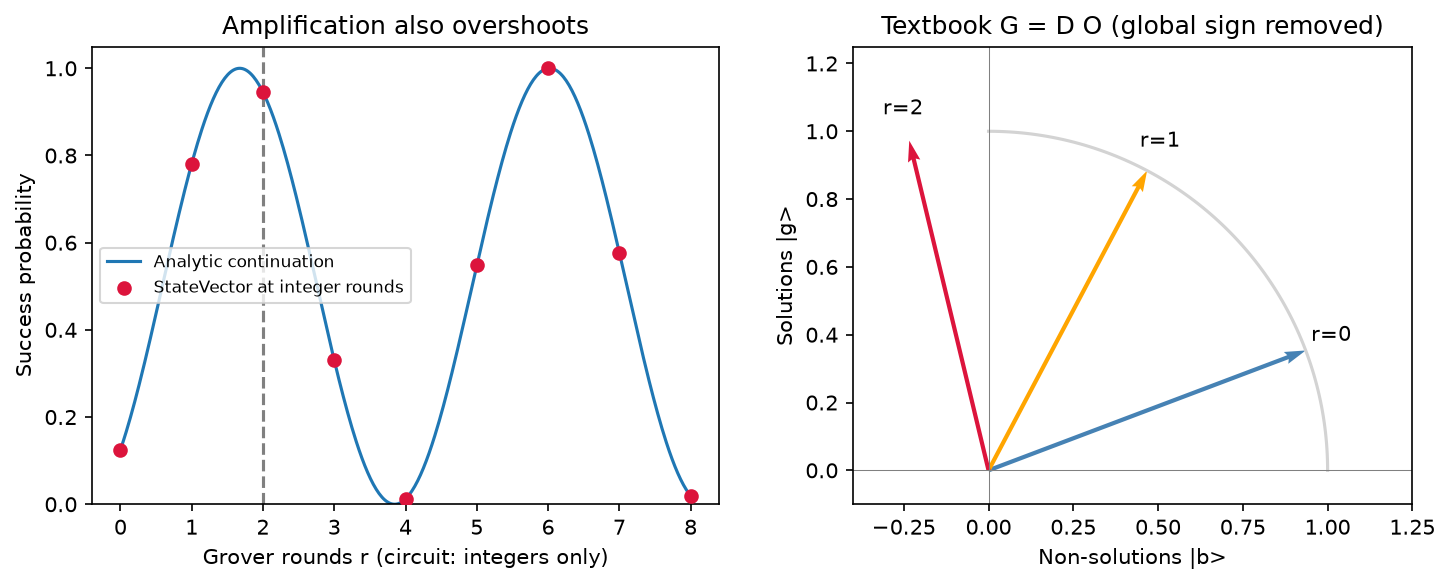

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
dense_rounds = np.linspace(0, 8, 400)
axes[0].plot(dense_rounds, np.sin((2*dense_rounds+1)*grover_theta)**2, label="Analytic continuation")
axes[0].scatter(grover_rounds, grover_simulated, color="crimson", label="StateVector at integer rounds", zorder=3)
axes[0].axvline(iterations, color="gray", linestyle="--")
axes[0].set(xlabel="Grover rounds r (circuit: integers only)", ylabel="Success probability", ylim=(0, 1.05), title="Amplification also overshoots")
axes[0].legend(fontsize=8)
axes[1].set_aspect("equal")
arc = np.linspace(0, np.pi/2, 100)
axes[1].plot(np.cos(arc), np.sin(arc), color="lightgray")
for r in range(3):
    angle = (2*r+1)*grover_theta
    axes[1].quiver(0, 0, np.cos(angle), np.sin(angle), angles="xy", scale_units="xy", scale=1, color=["steelblue", "orange", "crimson"][r])
    axes[1].text(np.cos(angle)*1.08, np.sin(angle)*1.08, f"r={r}", ha="center")
axes[1].axhline(0, color="gray", linewidth=0.5)
axes[1].axvline(0, color="gray", linewidth=0.5)
axes[1].set(xlabel="Non-solutions |b>", ylabel="Solutions |g>", xlim=(-0.4, 1.25), ylim=(-0.1, 1.25), title="Textbook G = D O (global sign removed)")
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(data=buffer.getvalue()))


### B.6 加速的范围、练习与资料扩展

当 $M\ll N$ 时，搜索需要 $O(\sqrt{N/M})$ 次 oracle 查询；经典均匀抽样需要 $O(N/M)$ 次才能以常数概率找到解。这是黑盒查询模型下的平方级改进，不是指数加速，也不包含数据装载、oracle 实现、辅助位清理、编译和纠错的全部成本。这里在经典计算机上模拟振幅，不会获得实际的量子运行时间优势。

练习：

1. 把 `dst` 改为非回文的 `'001'`，从头运行，确认放大的是索引 1，而非 4；只改 `dst` 而不重建 `prog` 不会改变旧程序。
2. 取 $N=4,M=1$，手算 $\theta=\pi/6$，验证一轮成功率为 1。
3. 多解推广：在八维空间标记 `'001'` 与 `'110'`，将两个不同目标的 oracle 顺序连接，得到 $I-2\Pi_{\mathrm{good}}$；此时 $M=2$，一轮后总成功率为 1、每个目标概率为 $1/2$。同一目标重复标记两次会抵消，不能把重复条目计为两个解。

**教材定位（以下推导按本仓库代码重新组织）：**

- Nielsen、Chuang，*Quantum Computation and Quantum Information*, 10th Anniversary Edition (2010)，§6.1.1–6.1.4，印刷页 248–254，本地英文 PDF 第 282–288 页；相位回踢、均值反演、二维子空间和性能见式 (6.2)、(6.6)–(6.17)。其旋转角记号与本附录相差因子 2，见 B.3。
- 《量子计算与量子信息：10 周年版》（本地 2022 中文版），§6.1，印刷页 212–218，PDF 第 246–252 页，可对照同一组式号阅读。
- 郭国平、窦猛汉、陈昭昀，《QPanda 量子计算编程》(2024)，§5.1–5.2，印刷页 79–84，PDF 第 91–96 页；特别参照扩散算符整体负号的讨论。教材旧 `pyqpanda` 代码不直接用于本仓库。
- 原论文：[Grover, *A fast quantum mechanical algorithm for database search* (1996)](https://arxiv.org/abs/quant-ph/9605043)；未知解数和多解情形进一步读 [Boyer 等, *Tight bounds on quantum searching*](https://arxiv.org/abs/quant-ph/9605034)。

本地教材位于 `docs/pdf/`，已被 Git 忽略；附录保留定义、推导和可执行验证，不需要读者先取得这些 PDF。
